# **Q3. Camera-Lidar fusion (KITTI)**

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from ultralytics import YOLO

base_dir = Path.cwd()
data_dir = base_dir / "data" / "training"
ids = sorted(f.stem for f in (data_dir / "image_2").glob("*.png"))  #all samples in the folder
model = YOLO(str(base_dir / "yolo11n-seg.pt"))  #pretrained on COCO

def read_calib(sample_id):
  calib = {}
  for line in (data_dir / "calib" / f"{sample_id}.txt").read_text().splitlines():
    if ":" in line:
      key, values = line.split(":")
      calib[key] = np.array(values.split(), dtype=float)
  P2 = calib["P2"].reshape(3, 4)
  R0 = np.eye(4)
  R0[:3, :3] = calib["R0_rect"].reshape(3, 3)
  Tr = np.eye(4)
  Tr[:3, :4] = calib["Tr_velo_to_cam"].reshape(3, 4)
  return P2, R0, Tr

def project_lidar(sample_id, img_shape):
  """Lidar points -> pixel (u, v) and depth z in the camera frame, only points in front of the camera and inside the image."""
  points = np.fromfile(data_dir / "velodyne" / f"{sample_id}.bin", dtype=np.float32).reshape(-1, 4)
  P2, R0, Tr = read_calib(sample_id)
  p_lidar = np.hstack([points[:, :3], np.ones((len(points), 1))])  #homogeneous, N x 4
  p_cam = (R0 @ Tr @ p_lidar.T)  #4 x N, rectified camera frame
  p_pix = P2 @ p_cam  #3 x N
  z = p_pix[2]
  u, v = p_pix[0] / z, p_pix[1] / z
  h, w = img_shape[:2]
  keep = (z > 0) & (u >= 0) & (u < w) & (v >= 0) & (v < h)
  return u[keep], v[keep], z[keep]

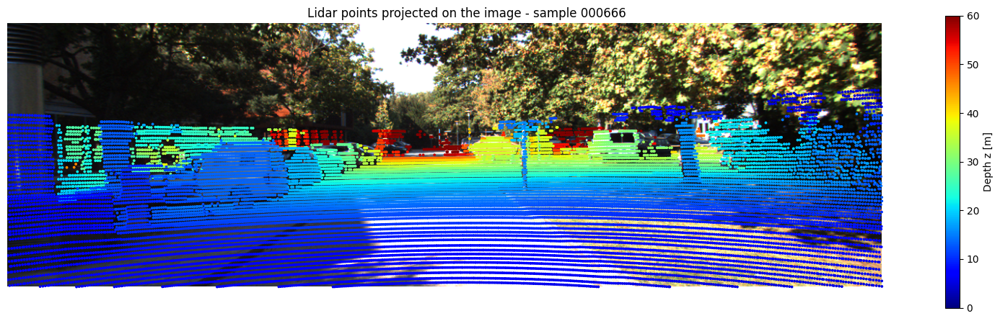

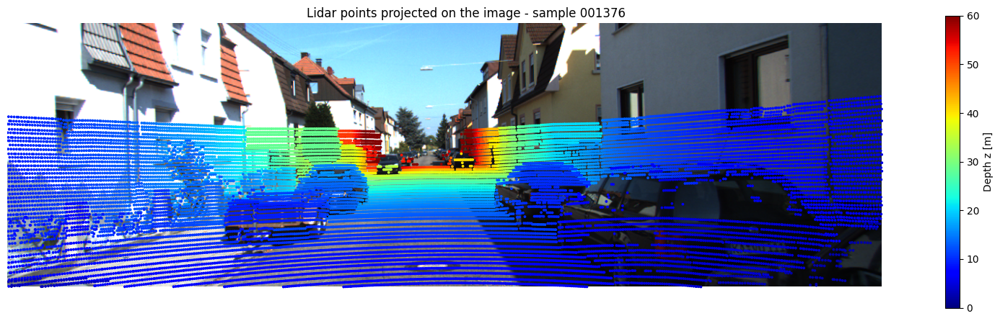

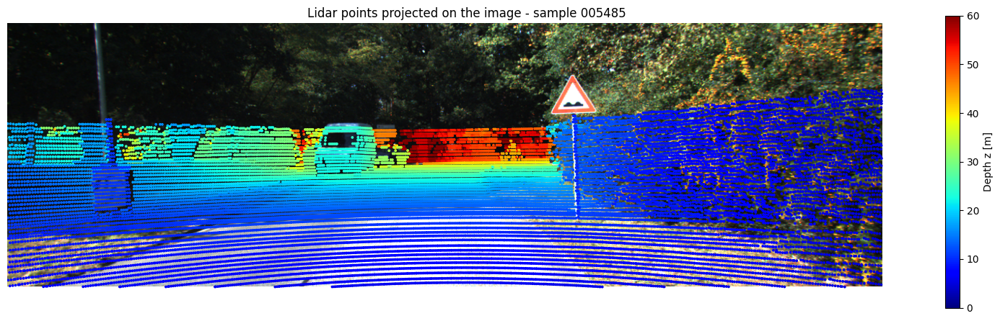

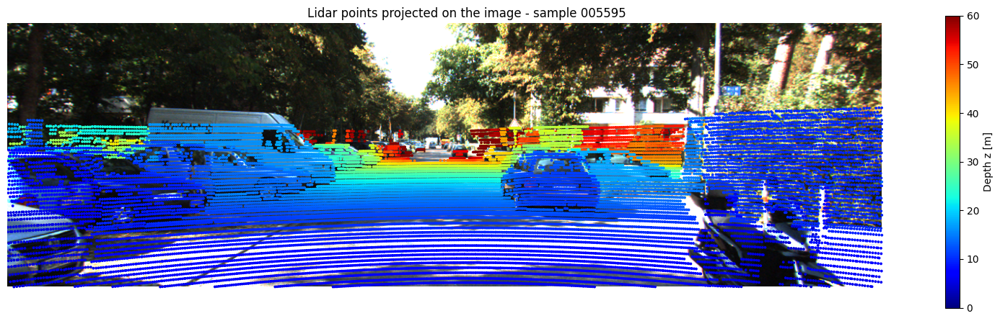

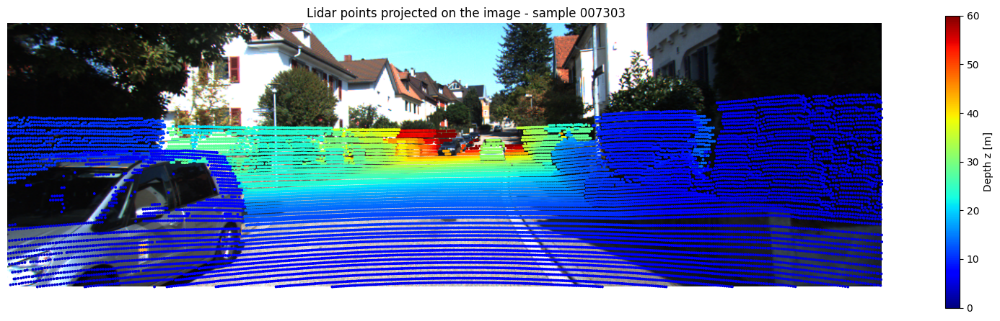

In [2]:
for sample_id in ids:
  img = np.array(Image.open(data_dir / "image_2" / f"{sample_id}.png"))
  u, v, z = project_lidar(sample_id, img.shape)

  plt.figure(figsize=(14, 4.5))
  plt.imshow(img)
  sc = plt.scatter(u, v, c=z, s=3, cmap="jet", vmin=0, vmax=60)
  plt.colorbar(sc, label="Depth z [m]", fraction=0.025, pad=0.02)
  plt.title(f"Lidar points projected on the image - sample {sample_id}")
  plt.axis("off")
  plt.tight_layout()
  plt.show()

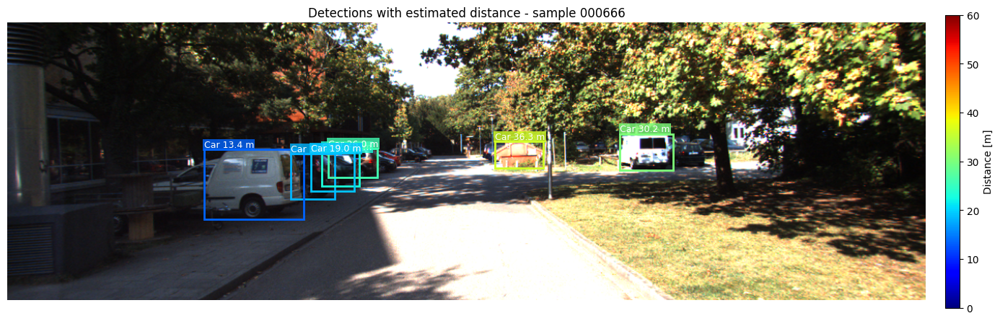

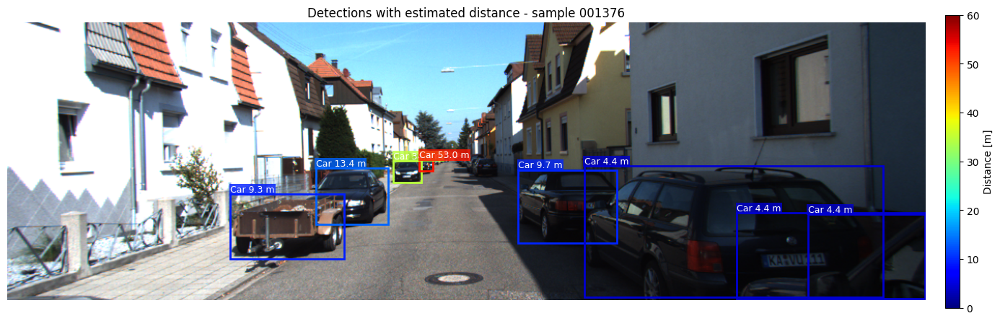

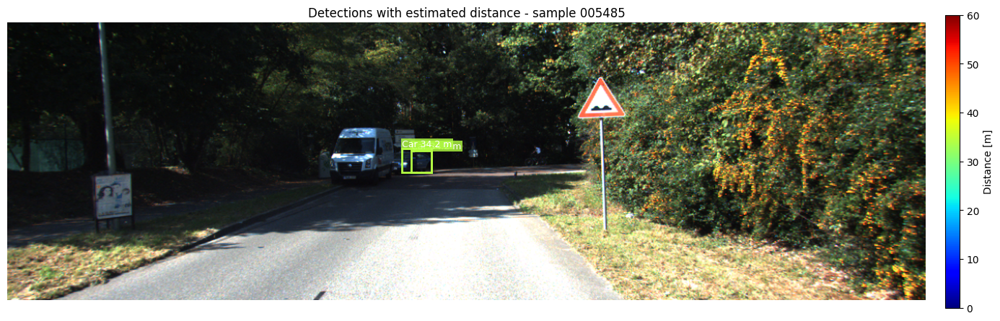

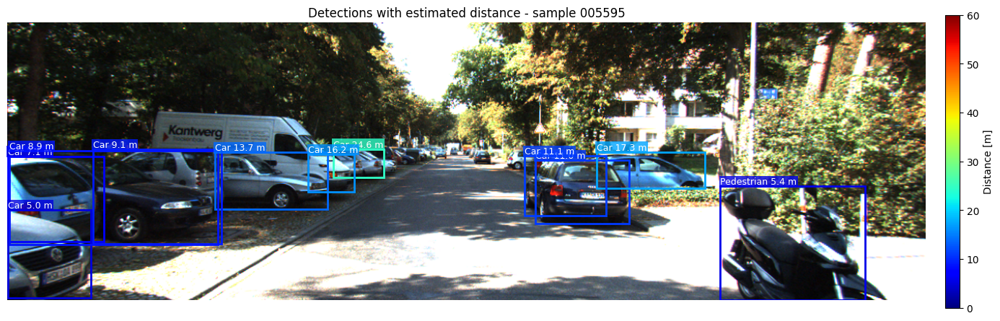

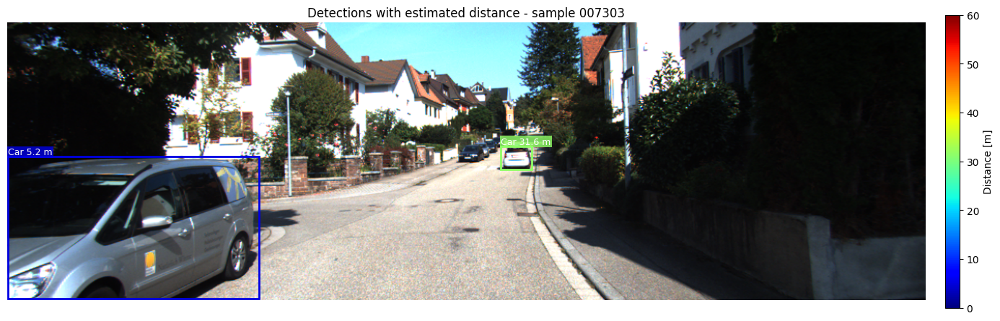

In [3]:
import matplotlib.patches as mpatches
from matplotlib import cm, colors

COCO_TO_KITTI = {0: "Pedestrian", 1: "Cyclist", 2: "Car"}  #person, bicycle, car

detections = []
for sample_id in ids:
  img = np.array(Image.open(data_dir / "image_2" / f"{sample_id}.png"))
  u, v, z = project_lidar(sample_id, img.shape)
  results = model(data_dir / "image_2" / f"{sample_id}.png", verbose=False)[0]

  for box, cls in zip(results.boxes.xyxy.cpu().numpy(), results.boxes.cls.cpu().numpy().astype(int)):
    if cls not in COCO_TO_KITTI:
      continue
    x1, y1, x2, y2 = box
    #central 50 % of the box
    cx, cy, w, h = (x1 + x2) / 2, (y1 + y2) / 2, (x2 - x1) / 2, (y2 - y1) / 2
    inside = (np.abs(u - cx) < w / 2) & (np.abs(v - cy) < h / 2)
    if inside.sum() < 3:
      continue
    detections.append({"sample": sample_id, "class": COCO_TO_KITTI[cls], "box": box, "distance": np.median(z[inside]), "n_points": int(inside.sum())})

norm = colors.Normalize(vmin=0, vmax=60)
for sample_id in ids:
  img = np.array(Image.open(data_dir / "image_2" / f"{sample_id}.png"))
  fig, ax = plt.subplots(figsize=(14, 4.5))
  ax.imshow(img)
  for d in [d for d in detections if d["sample"] == sample_id]:
    x1, y1, x2, y2 = d["box"]
    color = cm.jet(norm(d["distance"]))
    ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
    ax.text(x1, y1 - 3, f"{d['class']} {d['distance']:.1f} m", color="white", fontsize=9,
            bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))
  fig.colorbar(cm.ScalarMappable(norm=norm, cmap="jet"), ax=ax, label="Distance [m]", fraction=0.025, pad=0.02)
  ax.set_title(f"Detections with estimated distance - sample {sample_id}")
  ax.axis("off")
  plt.tight_layout()
  plt.show()

sample class  estimated [m]  ground truth [m]  error [m]  error [%]  center distance [px]
000666   Car          30.17             32.42      -2.25       -7.0                   4.3
000666   Car          18.09             23.80      -5.71      -24.0                   6.1
000666   Car          23.10             28.89      -5.79      -20.0                   7.8
000666   Car          13.40             18.79      -5.39      -28.7                  28.6
001376   Car          34.63             36.29      -1.66       -4.6                   1.1
001376   Car           4.45              6.35      -1.90      -29.9                  10.6
001376   Car          13.44             15.12      -1.68      -11.1                  10.9
001376   Car           9.74             11.63      -1.89      -16.3                  15.3
005595   Car           8.89              9.73      -0.84       -8.6                   3.6
005595   Car          10.99             13.07      -2.08      -15.9                   6.1
005595   C

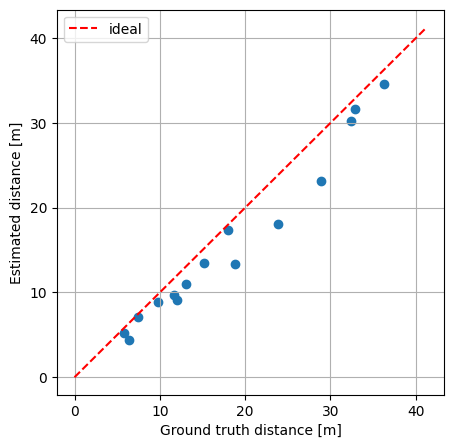

In [4]:
def center(box):
  return np.array([(box[0] + box[2]) / 2, (box[1] + box[3]) / 2])

rows = []
for sample_id in ids:
  labels = [l.split() for l in (data_dir / "label_2" / f"{sample_id}.txt").read_text().splitlines()]
  dets = [d for d in detections if d["sample"] == sample_id]

  #all possible pairs (same class, centers close enough), closest pairs are matched first
  pairs = []
  for di, d in enumerate(dets):
    size = max(d["box"][2] - d["box"][0], d["box"][3] - d["box"][1])
    for li, l in enumerate(labels):
      if l[0] != d["class"]:
        continue
      dist = np.linalg.norm(center(d["box"]) - center([float(x) for x in l[4:8]]))
      if dist < size / 4:
        pairs.append((dist, di, li))

  used_det, used_label = set(), set()
  for dist, di, li in sorted(pairs):
    if di in used_det or li in used_label:
      continue
    used_det.add(di)
    used_label.add(li)
    d, gt = dets[di], float(labels[li][13])  #location z in camera frame
    rows.append({"sample": sample_id, "class": d["class"], "estimated [m]": round(d["distance"], 2),
                 "ground truth [m]": round(gt, 2), "error [m]": round(d["distance"] - gt, 2),
                 "error [%]": round(100 * (d["distance"] - gt) / gt, 1), "center distance [px]": round(dist, 1)})

table = pd.DataFrame(rows)
print(table.to_string(index=False))
print(f"\nMean absolute error = {table['error [m]'].abs().mean():.2f} m, "
      f"RMSE = {np.sqrt((table['error [m]'] ** 2).mean()):.2f} m, matched {len(table)} of {len(detections)} detections")

plt.figure(figsize=(5, 5))
plt.scatter(table["ground truth [m]"], table["estimated [m]"])
lims = [0, max(table["ground truth [m]"].max(), table["estimated [m]"].max()) + 5]
plt.plot(lims, lims, "r--", label="ideal")
plt.xlabel("Ground truth distance [m]")
plt.ylabel("Estimated distance [m]")
plt.legend()
plt.grid(True)
plt.show()